In [1]:
!pip install -q easyocr opencv-python matplotlib


In [2]:
import cv2
import easyocr
import numpy as np
import matplotlib.pyplot as plt
import re
from google.colab import files

print("Libraries imported successfully")

Libraries imported successfully


Saving MED_F01_000570.jpg to MED_F01_000570.jpg


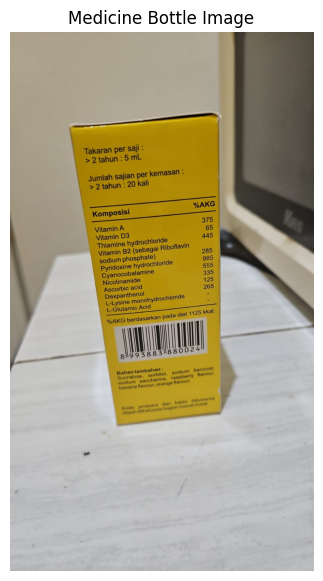

In [3]:
uploaded = files.upload()

file_name = next(iter(uploaded))

image_data = np.frombuffer(uploaded[file_name], np.uint8)
img = cv2.imdecode(image_data, cv2.IMREAD_COLOR)

plt.figure(figsize=(7, 7))
plt.imshow(cv2.cvtColor(img, cv2.COLOR_BGR2RGB))
plt.title("Medicine Bottle Image")
plt.axis("off")
plt.show()

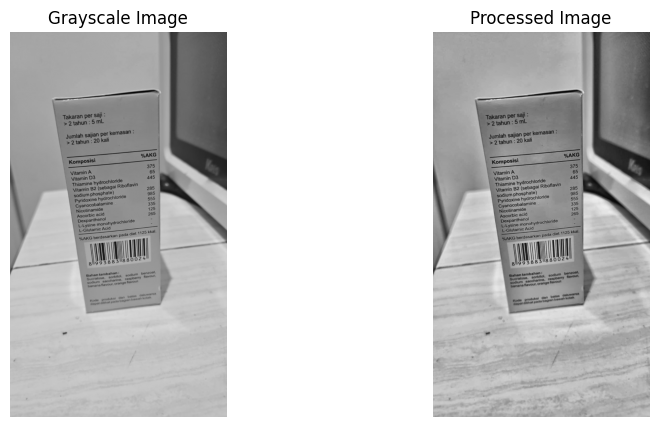

In [4]:
gray = cv2.cvtColor(img, cv2.COLOR_BGR2GRAY)

resized = cv2.resize(
    gray,
    None,
    fx=1.5,
    fy=1.5,
    interpolation=cv2.INTER_CUBIC
)

clahe = cv2.createCLAHE(
    clipLimit=2.0,
    tileGridSize=(8, 8)
)

processed = clahe.apply(resized)

plt.figure(figsize=(10, 5))

plt.subplot(1, 2, 1)
plt.imshow(gray, cmap="gray")
plt.title("Grayscale Image")
plt.axis("off")

plt.subplot(1, 2, 2)
plt.imshow(processed, cmap="gray")
plt.title("Processed Image")
plt.axis("off")

plt.show()

Progress: |██████████████████████████████████████████████████| 100.0% Complete

Progress: |██████████████████████████████████████████████████| 100.0% Complete

/usr/local/lib/python3.13/dist-packages/torch/ao/nn/quantized/dynamic/modules/rnn.py:162: UserWarning: torch.quantize_per_tensor, torch.quantize_per_channel and other quantized tensor creation functions that produce tensors with dtype torch.quint8, torch.qint8, and torch.qint32 are deprecated and will be removed in a future PyTorch release. Please see https://github.com/pytorch/pytorch/issues/184982 for more information. (Triggered internally at /__w/pytorch/pytorch/aten/src/ATen/quantized/Quantizer.cpp:111.)
  w_ih = torch.quantize_per_tensor(
/usr/local/lib/python3.13/dist-packages/torch/utils/data/dataloader.py:759: UserWarning: 'pin_memory' argument is set as true but no accelerator is found, then device pinned memory won't be used.
  super().__init__(loader)


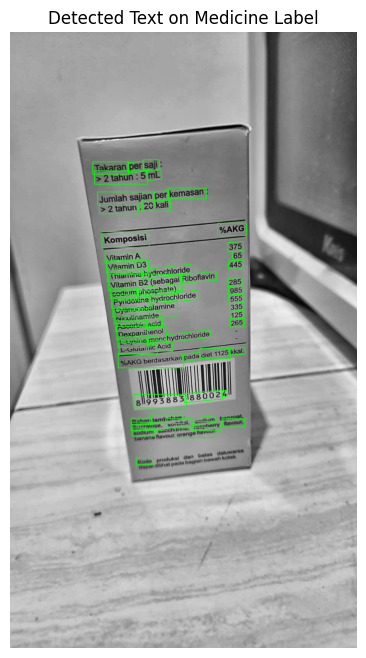

Text detection completed


In [5]:
reader = easyocr.Reader(['en'], gpu=False)

results = reader.readtext(processed)

detected_text = []

display_img = cv2.cvtColor(processed, cv2.COLOR_GRAY2BGR)

for box, text, confidence in results:

    if confidence > 0.25:

        detected_text.append(text)

        points = np.array(box, dtype=np.int32)

        cv2.polylines(
            display_img,
            [points],
            True,
            (0, 255, 0),
            2
        )

plt.figure(figsize=(10, 8))
plt.imshow(cv2.cvtColor(display_img, cv2.COLOR_BGR2RGB))
plt.title("Detected Text on Medicine Label")
plt.axis("off")
plt.show()

print("Text detection completed")

In [6]:
full_text = "\n".join(detected_text)

print("EXTRACTED MEDICINE LABEL TEXT")
print("-" * 40)

if full_text:
    print(full_text)
else:
    print("No readable text found")

print("\nIndividual OCR Results:")

for i, (box, text, confidence) in enumerate(results):

    print(
        f"{i+1}. {text} | Confidence: {confidence:.2f}"
    )

EXTRACTED MEDICINE LABEL TEXT
----------------------------------------
Takaran 
saji
>2 tahun : 5
Jumlah sajian
kemasan
> 2 tahun
20 kali
%AKG
Komposisi
Vitamin A
65
Vitamin D3
445
Thiamine
Vitamin B2 (sebagai
285
sodium
Pyridoxine 
Cyanocobalamine
Nicotinamide
Ascorbic
265
Dexpanthenol
L-Lysine
Acid
LGlutamic
diet 1125
%AKG berdasarkan
4
8ls93883
Itambahan
Bahan
sorbilol;
Navour:
Sucralose,
raspbemy
sodium
oranga (avour
Kode
per
mL
per
375
hydrochloride
Riboflavin
phosphate)
985
hydrochloride
555
335
125
acid
monohydrochloride
kkal:
pada
18 8002
sodium

Individual OCR Results:
1. Takaran  | Confidence: 0.63
2. saji | Confidence: 0.71
3. >2 tahun : 5 | Confidence: 0.58
4. Jumlah sajian | Confidence: 0.71
5. kemasan | Confidence: 1.00
6. > 2 tahun | Confidence: 0.38
7. 20 kali | Confidence: 1.00
8. %AKG | Confidence: 0.99
9. Komposisi | Confidence: 1.00
10. Vitamin A | Confidence: 0.62
11. 65 | Confidence: 1.00
12. Vitamin D3 | Confidence: 0.82
13. 445 | Confidence: 1.00
14. Thiamine | 

In [7]:
def extract_info(pattern, text):

    match = re.search(pattern, text, re.IGNORECASE)

    if match:
        return match.group(1)

    return "Not detected"


medicine_name = detected_text[0] if detected_text else "Not detected"

strength = extract_info(
    r"([0-9]+\s?(?:mg|mcg|g|ml|%))",
    full_text
)

batch = extract_info(
    r"(?:batch|lot)\s*(?:no\.?|number)?\s*[:#-]?\s*([A-Z0-9/-]+)",
    full_text
)

expiry = extract_info(
    r"(?:exp(?:iry)?\.?\s*date?)\s*[:#-]?\s*([A-Z0-9/-]+)",
    full_text
)

manufacturing = extract_info(
    r"(?:mfg|manufactured)\s*(?:date)?\s*[:#-]?\s*([A-Z0-9/-]+)",
    full_text
)

print("MEDICINE INFORMATION")
print("=" * 40)

print("Possible Medicine Name:", medicine_name)
print("Strength:", strength)
print("Batch Number:", batch)
print("Expiry Date:", expiry)
print("Manufacturing Date:", manufacturing)

MEDICINE INFORMATION
Possible Medicine Name: Takaran 
Strength: 1125
%
Batch Number: Not detected
Expiry Date: Not detected
Manufacturing Date: Not detected


In [8]:
print("MEDICINE LABEL READING ASSISTANT")
print("=" * 45)

if len(detected_text) == 0:

    print("Unable to read the medicine label.")
    print("Please upload a clearer image.")

else:

    print("Medicine label successfully scanned!\n")

    print("Possible Medicine Name:", medicine_name)
    print("Strength:", strength)
    print("Batch Number:", batch)
    print("Expiry Date:", expiry)
    print("Manufacturing Date:", manufacturing)

    print("\nPlease verify all extracted information")
    print("with the original medicine bottle.")

MEDICINE LABEL READING ASSISTANT
Medicine label successfully scanned!

Possible Medicine Name: Takaran 
Strength: 1125
%
Batch Number: Not detected
Expiry Date: Not detected
Manufacturing Date: Not detected

Please verify all extracted information
with the original medicine bottle.


In [4]:
!pip install -q deepface tf-keras

!pip uninstall -y opencv-python opencv-python-headless opencv-contrib-python opencv-contrib-python-headless

!pip install -q --no-cache-dir opencv-contrib-python-headless==4.10.0.84

Found existing installation: opencv-contrib-python-headless 4.10.0.84
Uninstalling opencv-contrib-python-headless-4.10.0.84:
  Successfully uninstalled opencv-contrib-python-headless-4.10.0.84


In [1]:
import cv2
import numpy as np
import matplotlib.pyplot as plt

from deepface import DeepFace
from google.colab import files

print("OpenCV Version:", cv2.__version__)
print("DeepFace imported successfully")

print("Cascade Classifier Available:",
      hasattr(cv2, "CascadeClassifier"))

OpenCV Version: 4.10.0
DeepFace imported successfully
Cascade Classifier Available: True


Saving happy.png to happy (1).png
Image uploaded successfully!
Image Shape: (4133, 3000, 3)


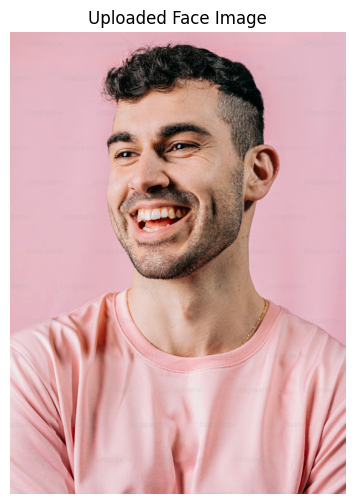

In [4]:
from google.colab import files
from PIL import Image
import matplotlib.pyplot as plt
import numpy as np
import cv2

uploaded = files.upload()

file_name = next(iter(uploaded))

try:
    face_img = np.array(Image.open(file_name).convert("RGB"))

    face_img = cv2.cvtColor(face_img, cv2.COLOR_RGB2BGR)

    print("Image uploaded successfully!")
    print("Image Shape:", face_img.shape)

    plt.figure(figsize=(6, 6))

    plt.imshow(cv2.cvtColor(face_img, cv2.COLOR_BGR2RGB))

    plt.title("Uploaded Face Image")

    plt.axis("off")

    plt.show()

except Exception as e:
    print("Unable to read image:", e)

In [5]:
analysis = DeepFace.analyze(
    img_path=face_img,
    actions=['emotion'],
    detector_backend='opencv',
    enforce_detection=True,
    silent=True
)

26-11-21 09:16:43 - 🔗 facial_expression_model_weights.h5 will be downloaded from https://github.com/serengil/deepface_models/releases/download/v1.0/facial_expression_model_weights.h5 to /root/.deepface/weights/facial_expression_model_weights.h5...


Downloading...
From: https://github.com/serengil/deepface_models/releases/download/v1.0/facial_expression_model_weights.h5
To: /root/.deepface/weights/facial_expression_model_weights.h5
100%|██████████| 5.98M/5.98M [00:00<00:00, 76.3MB/s]


In [6]:
try:

    analysis = DeepFace.analyze(
        img_path=face_img,
        actions=['emotion'],
        detector_backend='opencv',
        enforce_detection=True,
        silent=True
    )

    if isinstance(analysis, list):
        result = analysis[0]
    else:
        result = analysis

    dominant_emotion = result['dominant_emotion']

    emotion_scores = result['emotion']

    print("Dominant Emotion:", dominant_emotion)

    print("\nEmotion Scores:")

    for emotion, score in emotion_scores.items():

        print(f"{emotion}: {score:.2f}")

except Exception as e:

    print("Error in emotion detection:", e)

    result = None

Dominant Emotion: happy

Emotion Scores:
angry: 0.00
disgust: 0.00
fear: 0.01
happy: 99.99
sad: 0.00
surprise: 0.00
neutral: 0.00


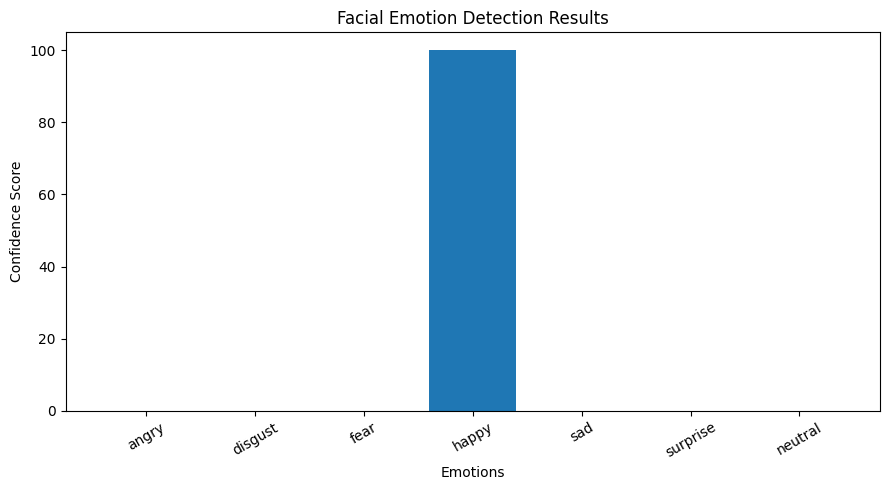

In [7]:
if result is not None:

    emotions = list(result['emotion'].keys())

    scores = list(result['emotion'].values())

    plt.figure(figsize=(9, 5))

    plt.bar(emotions, scores)

    plt.xlabel("Emotions")

    plt.ylabel("Confidence Score")

    plt.title("Facial Emotion Detection Results")

    plt.xticks(rotation=30)

    plt.tight_layout()

    plt.show()

In [8]:
if result is not None:

    print("EMOTION AWARE COGNITIVE ASSISTANT")

    print("=" * 45)

    print("Dominant Emotion:", result['dominant_emotion'])

    print("\nDetailed Emotion Analysis:")

    for emotion, score in sorted(
        result['emotion'].items(),
        key=lambda x: x[1],
        reverse=True
    ):

        print(f"{emotion}: {score:.2f}")

    print("\nFacial expression analysis completed.")

    print("These results are model predictions,")
    print("not confirmation of the person's actual feelings.")

EMOTION AWARE COGNITIVE ASSISTANT
Dominant Emotion: happy

Detailed Emotion Analysis:
happy: 99.99
fear: 0.01
neutral: 0.00
sad: 0.00
surprise: 0.00
angry: 0.00
disgust: 0.00

Facial expression analysis completed.
These results are model predictions,
not confirmation of the person's actual feelings.
